## Cellpose-SAM: superhuman generalization for cellular segmentation

Marius Pachitariu, Michael Rariden, Carsen Stringer

[paper](https://www.biorxiv.org/content/10.1101/2025.04.28.651001v1) | [code](https://github.com/MouseLand/cellpose)

This notebook shows how to process your own 2D or 3D images, saved on Google Drive.

This notebook is adapted from the notebook by Pradeep Rajasekhar, inspired by the [ZeroCostDL4Mic notebook series](https://github.com/HenriquesLab/ZeroCostDL4Mic/wiki).

### Make sure you have GPU access enabled by going to Runtime -> Change Runtime Type -> Hardware accelerator and selecting GPU

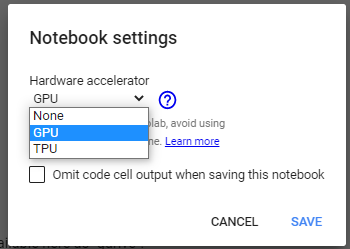

### Install Cellpose-SAM


In [ ]:
!uv pip install git+https://www.github.com/mouseland/cellpose.git

Check GPU and instantiate model - will download weights.

In [1]:
import numpy as np
from cellpose import models, core, io, plot
from pathlib import Path
from tqdm import trange
import matplotlib.pyplot as plt

io.logger_setup() # run this to get printing of progress

#Check if colab notebook instance has GPU access
if core.use_gpu()==False:
  raise ImportError("No GPU access, change your runtime")

model = models.CellposeModel(gpu=True)

[GUI INFO] : WRITING LOG OUTPUT TO C:\Users\20223228\.cellpose\run.log

cellpose version: 	4.2.1.1 
platform:       	win32 
python version: 	3.12.14 
torch version:  	2.14.0+cu126
2026-10-02 09:46:47,370 [io INFO] WRITING LOG OUTPUT TO C:\Users\20223228\.cellpose\run.log
2026-10-02 09:46:47,371 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	win32 
python version: 	3.12.14 
torch version:  	2.14.0+cu126
2026-10-02 09:46:48,916 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-02 09:46:48,918 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-02 09:46:48,918 [core INFO] >>>> using GPU (CUDA)
2026-10-02 09:46:51,260 [models INFO] >>>> loading model C:\Users\20223228\.cellpose\models\cpsam_v2


Input directory with your images (if you have them, otherwise use sample images):

In [20]:
# *** change to train folder path ***
train_dir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\train"
if not Path(train_dir).exists():
  raise FileNotFoundError("directory does not exist")

test_dir = "C:\\Users\\20223228\\OneDrive - TU Eindhoven\\Documents\\Vakken\\BEP\\Cellpose\\test\\andere_test" # optionally you can specify a directory with test files

# *** change to your mask extension ***
masks_ext = "_seg.npy"
# ^ assumes images from Cellpose GUI, if labels are tiffs, then "_masks.tif"

# list all files
files = [f for f in Path(train_dir).glob("*") if "_masks" not in f.name and "_flows" not in f.name and "_seg" not in f.name]

if(len(files)==0):
  raise FileNotFoundError("no files found, did you specify the correct folder and extension?")
else:
  print(f"{len(files)} files in training folder:")

for f in files:
  print(f.name)

1 files in training folder:
Composite3_Cy5greendapibluepcred8bit.tif


## Train new model

In [21]:
from cellpose import train

model_name = "new_model"

# default training params
n_epochs = 1 #usually 500-1000, but can be lower for testing. default was 100
learning_rate = 1e-5
weight_decay = 0.1
batch_size = 1

# get files
output = io.load_train_test_data(train_dir, test_dir, mask_filter=masks_ext)
train_data, train_labels, _, test_data, test_labels, _ = output
# (not passing test data into function to speed up training)

new_model_path, train_losses, test_losses = train.train_seg(model.net,
                                                            train_data=train_data,
                                                            train_labels=train_labels,
                                                            batch_size=batch_size,
                                                            n_epochs=n_epochs,
                                                            learning_rate=learning_rate,
                                                            weight_decay=weight_decay,
                                                            nimg_per_epoch=max(2, len(train_data)), # can change this
                                                            model_name=model_name)


2026-10-02 10:58:13,588 [io INFO] not all flows are present, running flow generation for all images
2026-10-02 10:58:13,672 [io INFO] 1 / 1 images in C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\train folder have labels
2026-10-02 10:58:13,675 [io INFO] not all flows are present, running flow generation for all images
2026-10-02 10:58:13,747 [io INFO] 1 / 1 images in C:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\test\andere_test folder have labels
2026-10-02 10:58:13,747 [dynamics INFO] computing flows for labels
2026-10-02 10:59:28,644 [train INFO] >>> computing diameters


100%|██████████| 1/1 [00:00<00:00, 39.72it/s]

2026-10-02 10:59:28,687 [train INFO] >>> normalizing {'lowhigh': None, 'percentile': None, 'normalize': True, 'norm3D': True, 'sharpen_radius': 0, 'smooth_radius': 0, 'tile_norm_blocksize': 0, 'tile_norm_smooth3D': 1, 'invert': False}
2026-10-02 10:59:28,844 [train INFO] >>> n_epochs=1, n_train=1, n_test=None, bsize=256, batch_size=1, nimg_per_epoch=2


2026-10-02 10:59:28,844 [train INFO] >>> AdamW, learning_rate=0.00001, weight_decay=0.10000
2026-10-02 10:59:28,844 [train INFO] >>> saving model to c:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\models\new_model
2026-10-02 11:00:00,464 [train INFO] 0, train_loss=2.7784, test_loss=0.0000, LR=0.000000, time 31.62s
2026-10-02 11:00:00,464 [train INFO] saving network parameters to c:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\models\new_model


## Evaluate on test data (optional)

If you have test data, check performance

In [22]:
from cellpose import metrics

model = models.CellposeModel(gpu=True,
                             pretrained_model=new_model_path)

# run model on test images
masks = model.eval(test_data, batch_size=1)[0] #default batch_size was 16, I changed to 1 to avoid memory issues. Other parameters can be changed as well

# check performance using ground truth labels
ap = metrics.average_precision(test_labels,masks,threshold=[0.5, 0.75, 0.9])[0]

aji = metrics.aggregated_jaccard_index(test_labels, masks)

precision, recall, fscore = metrics.boundary_scores(test_labels, masks, scales=[1.0])

print(f"AP50 = {ap[:,0].mean():.3f} ± {ap[:,0].std():.3f}")
print(f"AP75 = {ap[:,1].mean():.3f} ± {ap[:,1].std():.3f}")
print(f"AP90 = {ap[:,2].mean():.3f} ± {ap[:,2].std():.3f}")

print(f"AJI = {aji.mean():.3f} ± {aji.std():.3f}")

print(f"Boundary F-score = {fscore.mean():.3f} ± {fscore.std():.3f}")

2026-10-02 11:00:24,438 [core INFO] ** TORCH CUDA version installed and working. **
2026-10-02 11:00:24,439 [core INFO] >>>> using GPU (CUDA)
2026-10-02 11:00:26,770 [models INFO] >>>> loading model c:\Users\20223228\OneDrive - TU Eindhoven\Documents\Vakken\BEP\Cellpose\models\new_model
AP50 = 0.001 ± 0.000
AP75 = 0.000 ± 0.000
AP90 = 0.000 ± 0.000
AJI = 0.084 ± 0.000
Boundary F-score = 0.808 ± 0.000


plot masks

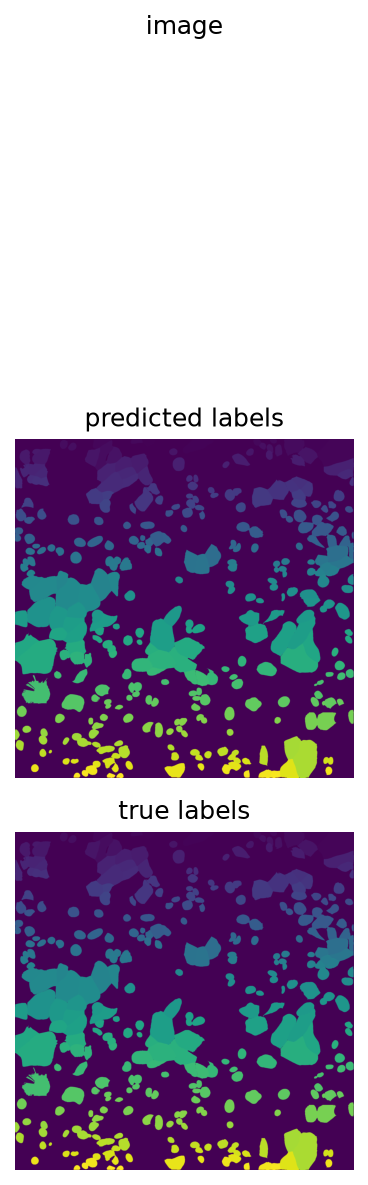

In [11]:
plt.figure(figsize=(12,8), dpi=150)
for k,im in enumerate(test_data):
    img = im.copy()
    plt.subplot(3,len(test_data), k+1)
    img = np.vstack((img, np.zeros_like(img)[:1]))
    img = img.transpose(1,2,0)
    plt.imshow(img)
    plt.axis('off')
    if k==0:
        plt.title('image')

    plt.subplot(3,len(test_data), len(test_data) + k+1)
    plt.imshow(masks[k])
    plt.axis('off')
    if k==0:
        plt.title('predicted labels')

    plt.subplot(3,len(test_data), 2*len(test_data) + k+1)
    plt.imshow(test_labels[k])
    plt.axis('off')
    if k==0:
        plt.title('true labels')
plt.tight_layout()